# Titanic Survival Prediction: End-to-End Data Science Project
**Goal:** predict whether a passenger survived the Titanic (binary classification), then deploy the model as a Streamlit web app on localhost.

**Pipeline:** Load & explore → Clean & transform → EDA → Feature selection → Model development → Cross-validation & tuning → Save model → Streamlit app

## 1. Data Collection and Exploration

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

from features import build_features, NUMERIC_FEATURES, CATEGORICAL_FEATURES, BINARY_FEATURES, ALL_FEATURES, SEX_MAP, EMBARKED_MAP

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
# Load the dataset with Pandas
df_raw = pd.read_csv("data/train_and_test2.csv")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (1309, 28)


,Passengerid,Age,Fare,Sex,sibsp,zero,zero.1,zero.2,zero.3,zero.4,...,zero.12,zero.13,zero.14,Pclass,zero.15,zero.16,Embarked,zero.17,zero.18,2urvived
0,1,22.0,7.2500,0,1,0,0,0,0,0,...,0,0,0,3,0,0,2.0,0,0,0
1,2,38.0,71.2833,1,1,0,0,0,0,0,...,0,0,0,1,0,0,0.0,0,0,1
2,3,26.0,7.9250,1,0,0,0,0,0,0,...,0,0,0,3,0,0,2.0,0,0,1
3,4,35.0,53.1000,1,1,0,0,0,0,0,...,0,0,0,1,0,0,2.0,0,0,1
4,5,35.0,8.0500,0,0,0,0,0,0,0,...,0,0,0,3,0,0,2.0,0,0,0


In [3]:
# Structure, data types, summary statistics
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 28 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Passengerid  1309 non-null   int64  
 1   Age          1309 non-null   float64
 2   Fare         1309 non-null   float64
 3   Sex          1309 non-null   int64  
 4   sibsp        1309 non-null   int64  
 5   zero         1309 non-null   int64  
 6   zero.1       1309 non-null   int64  
 7   zero.2       1309 non-null   int64  
 8   zero.3       1309 non-null   int64  
 9   zero.4       1309 non-null   int64  
 10  zero.5       1309 non-null   int64  
 11  zero.6       1309 non-null   int64  
 12  Parch        1309 non-null   int64  
 13  zero.7       1309 non-null   int64  
 14  zero.8       1309 non-null   int64  
 15  zero.9       1309 non-null   int64  
 16  zero.10      1309 non-null   int64  
 17  zero.11      1309 non-null   int64  
 18  zero.12      1309 non-null   int64  
 19  zero.13      1309

In [4]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Passengerid,1309.0,655.00,378.02,1.00,328.0,655.00,982.00,1309.00
Age,1309.0,29.50,12.91,0.17,22.0,28.00,35.00,80.00
Fare,1309.0,33.28,51.74,0.00,7.9,14.45,31.28,512.33
Sex,1309.0,0.36,0.48,0.00,0.0,0.00,1.00,1.00
sibsp,1309.0,0.50,1.04,0.00,0.0,0.00,1.00,8.00
zero,1309.0,0.00,0.00,0.00,0.0,0.00,0.00,0.00
zero.1,1309.0,0.00,0.00,0.00,0.0,0.00,0.00,0.00
zero.2,1309.0,0.00,0.00,0.00,0.0,0.00,0.00,0.00
zero.3,1309.0,0.00,0.00,0.00,0.0,0.00,0.00,0.00
zero.4,1309.0,0.00,0.00,0.00,0.0,0.00,0.00,0.00


In [5]:
# Potential issues: missing values, constant columns, label problems
print("Missing values (non-zero only):")
print(df_raw.isna().sum()[df_raw.isna().sum() > 0])

zero_cols = [c for c in df_raw.columns if df_raw[c].nunique() == 1]
print(f"\nConstant (zero-variance) columns: {len(zero_cols)} ->", zero_cols[:4], "...")

print("\nSurvival rate in first 891 rows :", round(df_raw.iloc[:891]['2urvived'].mean(), 3))
print("Survivors in last 418 rows       :", df_raw.iloc[891:]['2urvived'].sum())

Missing values (non-zero only):
Embarked    2
dtype: int64

Constant (zero-variance) columns: 19 -> ['zero', 'zero.1', 'zero.2', 'zero.3'] ...

Survival rate in first 891 rows : 0.384
Survivors in last 418 rows       : 0


**Issues found**
1. **19 columns are constant (all zeros)** (`zero`, `zero.1` … `zero.18`). They carry no information.
2. **Target column is misspelled** (`2urvived`). We rename it to `Survived`.
3. **Fake labels:** this file is the Kaggle train + test sets stacked together. The last 418 rows (the test set) have *no survivors at all* because their true labels were never known and were filled with 0. Training on them would teach the model false information, so we keep only the first 891 real, labeled rows.
4. **2 missing values** in `Embarked`.
5. **Outliers** in `Fare` (max about 512 vs median about 14) and some in `Age`/`sibsp`/`Parch`.
6. `Sex` and `Embarked` are already numerically encoded (Sex: 0=male, 1=female; Embarked: 0=C, 1=Q, 2=S).

## 2. Data Cleaning and Transformation

In [6]:
# Keep only the real labeled rows, drop constant columns and ID, fix the target name
df = df_raw.iloc[:891].copy()
df = df.drop(columns=zero_cols + ["Passengerid"])
df = df.rename(columns={"2urvived": "Survived"})
print("Shape after cleaning columns/rows:", df.shape)
df.columns.tolist()

Shape after cleaning columns/rows: (891, 8)


['Age', 'Fare', 'Sex', 'sibsp', 'Parch', 'Pclass', 'Embarked', 'Survived']

In [7]:
# Missing values: Embarked has 2 -> impute with the most frequent port (mode)
print("Missing Embarked before:", df["Embarked"].isna().sum())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
print("Missing Embarked after :", df["Embarked"].isna().sum())
print("Total missing values   :", df.isna().sum().sum())

Missing Embarked before: 2
Missing Embarked after : 0
Total missing values   : 0


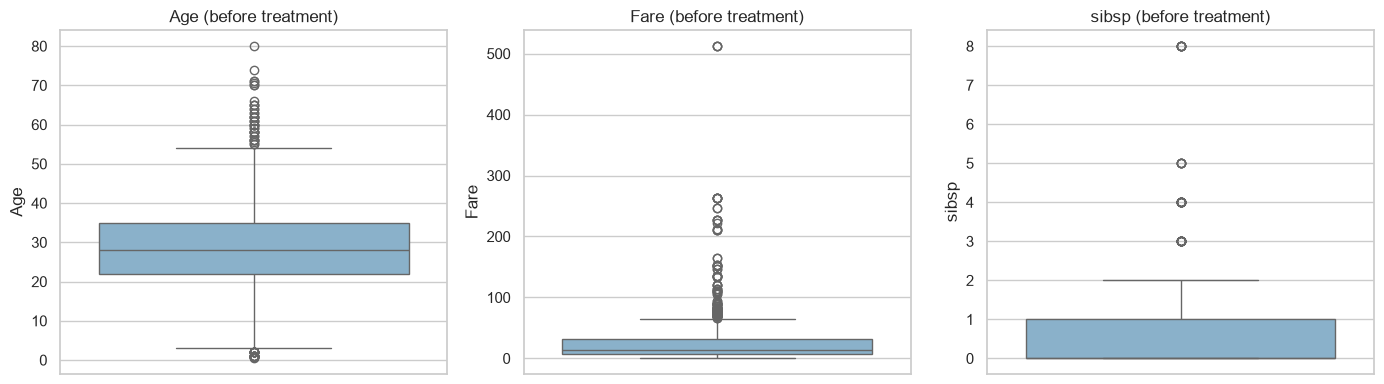

Age: 66 IQR outliers (7.4%)
Fare: 116 IQR outliers (13.0%)


In [8]:
# Outlier detection: boxplots + IQR rule
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Age", "Fare", "sibsp"]):
    sns.boxplot(y=df[col], ax=ax, color="#7fb3d5"); ax.set_title(f"{col} (before treatment)")
plt.tight_layout(); plt.show()

for col in ["Age", "Fare"]:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()
    print(f"{col}: {n} IQR outliers ({n/len(df):.1%})")

**Outlier treatment:**
- **Fare** is heavily right-skewed (a few first-class tickets cost 200–500). Removing them would throw away real, informative passengers, so we apply a **log transform** (`log1p`), which pulls extreme values in without deleting rows.
- **Age** outliers (elderly passengers) are genuine values, so we keep them. Scaling later reduces their influence on distance-based models like KNN.

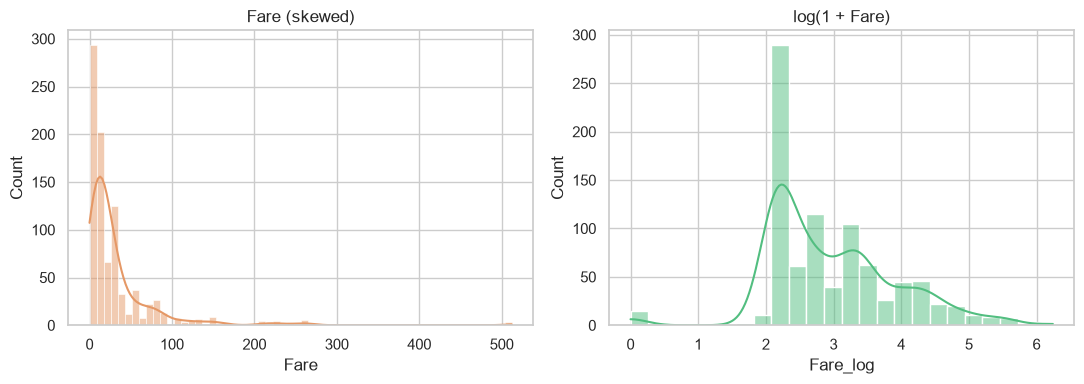

Skew before: 4.79 | after: 0.39


In [9]:
# Data transformation + feature creation (shared function in features.py)
df["Fare_log"] = np.log1p(df["Fare"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Fare"], kde=True, ax=axes[0], color="#e59866"); axes[0].set_title("Fare (skewed)")
sns.histplot(df["Fare_log"], kde=True, ax=axes[1], color="#52be80"); axes[1].set_title("log(1 + Fare)")
plt.tight_layout(); plt.show()
print("Skew before:", round(df["Fare"].skew(), 2), "| after:", round(df["Fare_log"].skew(), 2))

In [10]:
# New features: FamilySize and IsAlone
df["FamilySize"] = df["sibsp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df[["sibsp", "Parch", "FamilySize", "IsAlone"]].head()

,sibsp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1


**Encoding & scaling plan** (done inside a scikit-learn `Pipeline` so there is no data leakage):
- `Pclass`, `Embarked`: **one-hot encoded**
- `Age`, `Fare_log`, `FamilySize`: **standardized** (`StandardScaler`)
- `Sex`, `IsAlone`: already binary (0/1)

## 3. Exploratory Data Analysis (EDA)

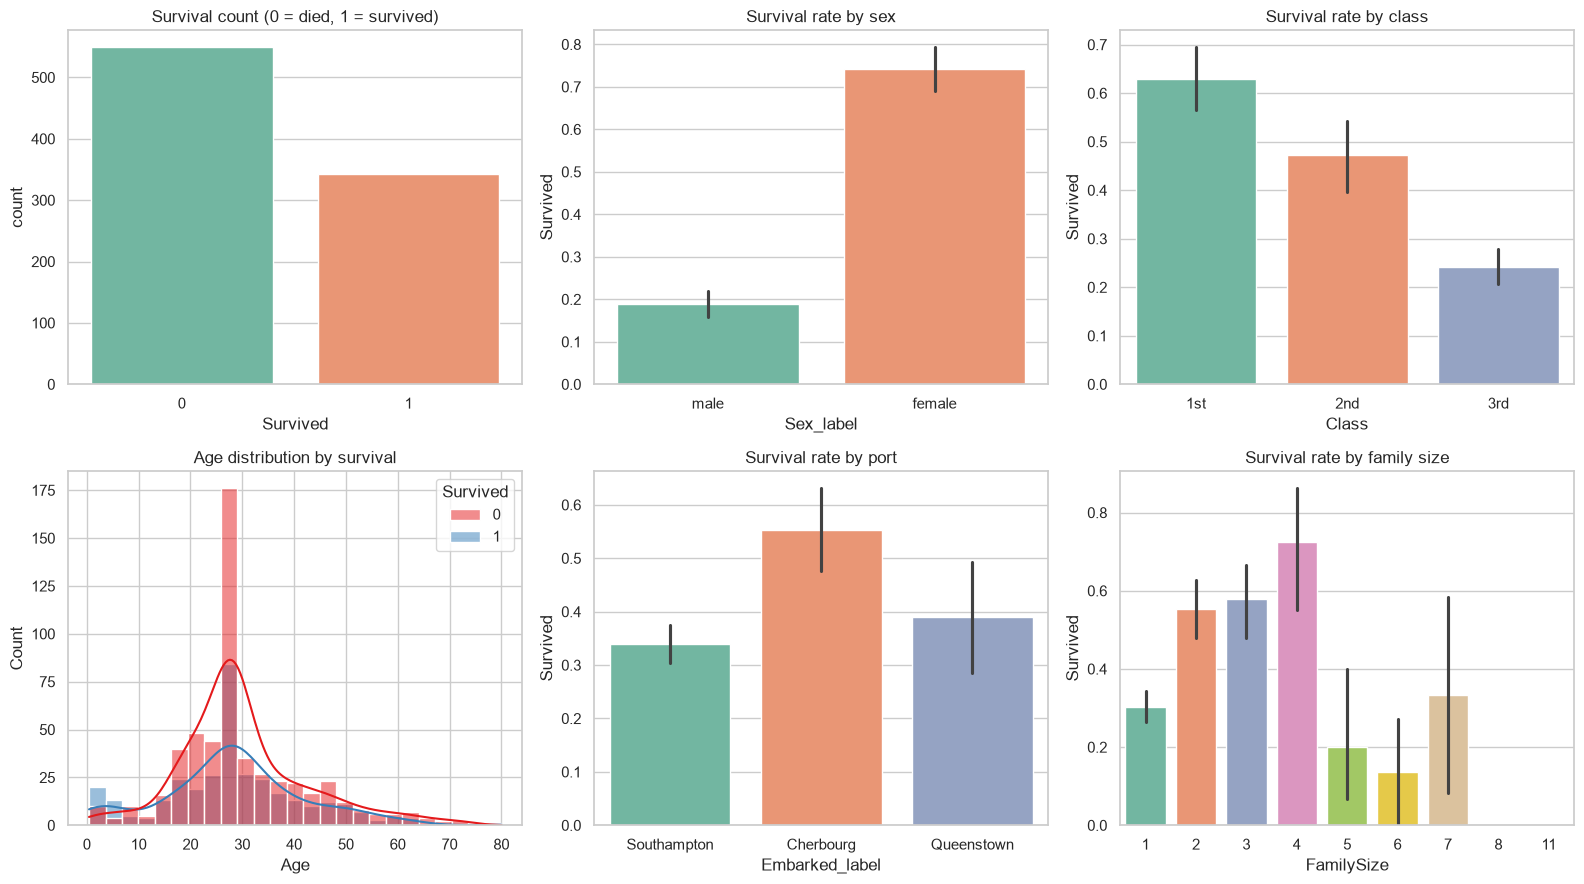

In [11]:
# Readable labels for plots
eda = df.copy()
eda["Sex_label"] = eda["Sex"].map(SEX_MAP)
eda["Embarked_label"] = eda["Embarked"].astype(int).map(EMBARKED_MAP)
eda["Class"] = eda["Pclass"].map({1: "1st", 2: "2nd", 3: "3rd"})

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sns.countplot(x="Survived", data=eda, ax=axes[0,0], palette="Set2"); axes[0,0].set_title("Survival count (0 = died, 1 = survived)")
sns.barplot(x="Sex_label", y="Survived", data=eda, ax=axes[0,1], palette="Set2"); axes[0,1].set_title("Survival rate by sex")
sns.barplot(x="Class", y="Survived", data=eda, order=["1st","2nd","3rd"], ax=axes[0,2], palette="Set2"); axes[0,2].set_title("Survival rate by class")
sns.histplot(data=eda, x="Age", hue="Survived", kde=True, bins=25, ax=axes[1,0], palette="Set1"); axes[1,0].set_title("Age distribution by survival")
sns.barplot(x="Embarked_label", y="Survived", data=eda, ax=axes[1,1], palette="Set2"); axes[1,1].set_title("Survival rate by port")
sns.barplot(x="FamilySize", y="Survived", data=eda, ax=axes[1,2], palette="Set2"); axes[1,2].set_title("Survival rate by family size")
plt.tight_layout(); plt.savefig("images/eda_overview.png", dpi=120); plt.show()

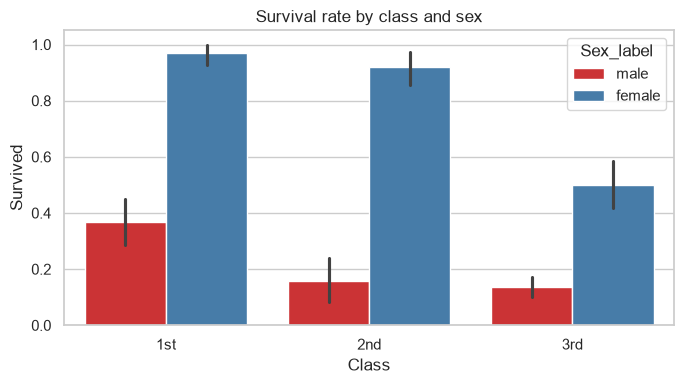

In [12]:
# Sex x Class interaction
plt.figure(figsize=(7, 4))
sns.barplot(x="Class", y="Survived", hue="Sex_label", data=eda, order=["1st","2nd","3rd"], palette="Set1")
plt.title("Survival rate by class and sex"); plt.tight_layout(); plt.savefig("images/sex_class.png", dpi=120); plt.show()

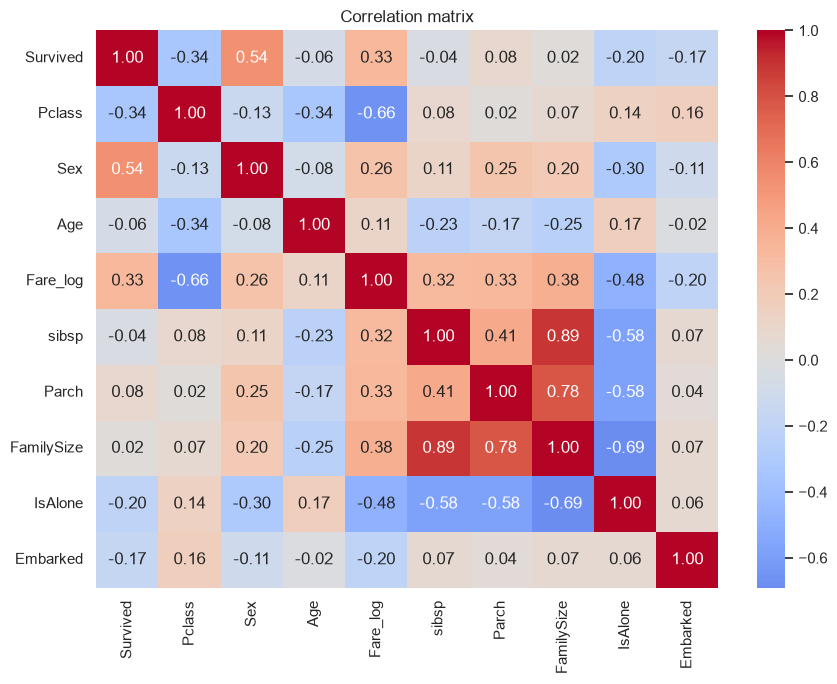

In [13]:
# Correlation heatmap
corr_cols = ["Survived", "Pclass", "Sex", "Age", "Fare_log", "sibsp", "Parch", "FamilySize", "IsAlone", "Embarked"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.tight_layout(); plt.savefig("images/correlation.png", dpi=120); plt.show()

In [14]:
print(eda.groupby("Sex_label")["Survived"].mean().round(3).to_string(), "\n")
print(eda.groupby("Class")["Survived"].mean().round(3).to_string(), "\n")
print("Child (<12) survival:", round(eda[eda.Age < 12]["Survived"].mean(), 3), "| Adult:", round(eda[eda.Age >= 12]["Survived"].mean(), 3))

Sex_label
female    0.742
male      0.189 

Class
1st    0.630
2nd    0.473
3rd    0.242 

Child (<12) survival: 0.574 | Adult: 0.368


## 4. Feature Selection

In [15]:
# Correlation of every candidate feature with the target
candidates = ["Pclass", "Sex", "Age", "Fare_log", "sibsp", "Parch", "FamilySize", "IsAlone", "Embarked"]
corr_target = df[candidates + ["Survived"]].corr()["Survived"].drop("Survived").sort_values(key=abs, ascending=False)
print(corr_target.round(3).to_string())

Sex           0.543
Pclass       -0.338
Fare_log      0.330
IsAlone      -0.203
Embarked     -0.168
Parch         0.082
Age          -0.065
sibsp        -0.035
FamilySize    0.017


In [16]:
# Redundancy check: sibsp, Parch and FamilySize overlap heavily
print(df[["sibsp", "Parch", "FamilySize"]].corr().round(2))

            sibsp  Parch  FamilySize
sibsp        1.00   0.41        0.89
Parch        0.41   1.00        0.78
FamilySize   0.89   0.78        1.00


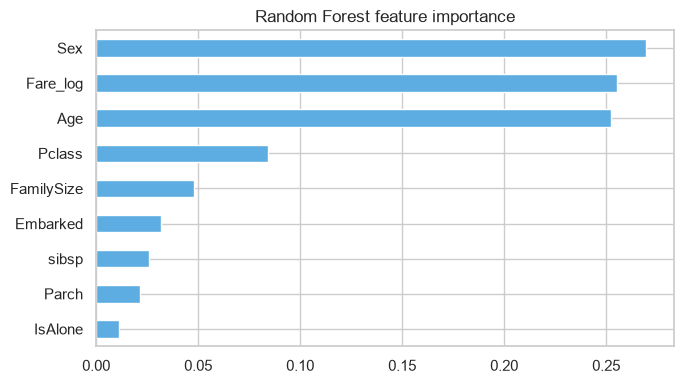

Sex           0.270
Fare_log      0.256
Age           0.252
Pclass        0.084
FamilySize    0.048
Embarked      0.032
sibsp         0.026
Parch         0.021
IsAlone       0.011


In [17]:
# Random Forest feature importance on all candidates
rf_sel = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(df[candidates], df["Survived"])
imp = pd.Series(rf_sel.feature_importances_, index=candidates).sort_values()
imp.plot.barh(figsize=(7, 4), color="#5dade2"); plt.title("Random Forest feature importance")
plt.tight_layout(); plt.savefig("images/feature_importance.png", dpi=120); plt.show()
print(imp.sort_values(ascending=False).round(3).to_string())

**Feature selection decision**
- **Keep:** `Sex`, `Pclass`, `Fare_log`, `Age`, `Embarked`, `FamilySize`, `IsAlone`
- **Drop:** `sibsp` and `Parch`. They are redundant because `FamilySize = sibsp + Parch + 1` already captures them, and they have weak correlation with survival on their own.
- Already removed earlier: 19 constant columns and `Passengerid`. That is the main dimensionality reduction (27 → 7 model features).

## 5. Model Development

In [18]:
# Build model features and split (80/20, stratified so class balance is preserved)
X = build_features(df_raw.iloc[:891].assign(Embarked=df["Embarked"]))
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Survival rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

Train: (712, 7) | Test: (179, 7)
Survival rate train/test: 0.383 0.385


In [19]:
# Preprocessing: scale numeric, one-hot categorical, pass binary through
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
        ("bin", "passthrough", BINARY_FEATURES),
    ])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN":                 KNeighborsClassifier(),
    "Naive Bayes":         GaussianNB(),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}
pipes = {name: Pipeline([("prep", make_preprocessor()), ("model", m)]) for name, m in models.items()}

# NaiveBayes needs dense input; ColumnTransformer with one-hot may return sparse -> force dense
for p in pipes.values():
    p.named_steps["prep"].set_params(sparse_threshold=0)

# Train + evaluate every model on the held-out test set
rows = []
for name, pipe in pipes.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})
baseline = pd.DataFrame(rows).set_index("Model").round(3)
baseline.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1
Model,,,,
Random Forest,0.810,0.778,0.710,0.742
Logistic Regression,0.804,0.783,0.681,0.729
Naive Bayes,0.749,0.650,0.754,0.698
KNN,0.771,0.726,0.652,0.687


## 6. Model Evaluation and Hyperparameter Tuning

In [20]:
# 5-fold stratified cross-validation (on training data only)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipe in pipes.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    cv_rows.append({"Model": name, "CV mean accuracy": scores.mean(), "CV std": scores.std()})
cv_table = pd.DataFrame(cv_rows).set_index("Model").round(3)
cv_table.sort_values("CV mean accuracy", ascending=False)

,CV mean accuracy,CV std
Model,,
KNN,0.801,0.010
Random Forest,0.801,0.021
Logistic Regression,0.794,0.016
Naive Bayes,0.772,0.026


In [21]:
# Hyperparameter tuning with Grid Search (scored on F1, as classes are imbalanced)
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100], "model__penalty": ["l2"]},
    "KNN": {"model__n_neighbors": [3, 5, 7, 9, 11, 15], "model__weights": ["uniform", "distance"]},
    "Naive Bayes": {"model__var_smoothing": np.logspace(-11, -5, 7)},
    "Random Forest": {"model__n_estimators": [100, 200, 400], "model__max_depth": [4, 6, 8, None],
                      "model__min_samples_leaf": [1, 3, 5]},
}
tuned, tune_rows = {}, []
for name, pipe in pipes.items():
    gs = GridSearchCV(pipe, param_grids[name], cv=cv, scoring="f1", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    pred = gs.best_estimator_.predict(X_test)
    tune_rows.append({"Model": name, "Best CV F1": gs.best_score_,
                      "Test Accuracy": accuracy_score(y_test, pred),
                      "Test Precision": precision_score(y_test, pred),
                      "Test Recall": recall_score(y_test, pred),
                      "Test F1": f1_score(y_test, pred),
                      "Best params": {k.replace("model__", ""): v for k, v in gs.best_params_.items()}})
results = pd.DataFrame(tune_rows).set_index("Model")
results.drop(columns="Best params").round(3).sort_values("Best CV F1", ascending=False)

,Best CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
Model,,,,,
Random Forest,0.755,0.804,0.815,0.638,0.715
KNN,0.742,0.788,0.731,0.710,0.721
Logistic Regression,0.722,0.804,0.783,0.681,0.729
Naive Bayes,0.713,0.749,0.650,0.754,0.698


In [22]:
# Final model comparison + selection
results[["Best params"]]

,Best params
Model,
Logistic Regression,"{'C': 1, 'penalty': 'l2'}"
KNN,"{'n_neighbors': 3, 'weights': 'uniform'}"
Naive Bayes,{'var_smoothing': 1e-11}
Random Forest,"{'max_depth': None, 'min_samples_leaf': 3, 'n_..."


Best model: Random Forest
Params    : {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 100}

Final test-set performance
              precision    recall  f1-score   support

        Died       0.80      0.91      0.85       110
    Survived       0.81      0.64      0.72        69

    accuracy                           0.80       179
   macro avg       0.81      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179



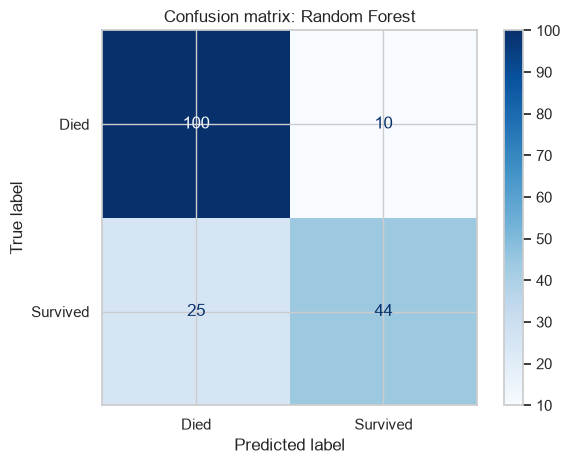

In [23]:
# Select best model by cross-validated F1 (NOT by test score, to avoid picking on the test set)
best_name = results["Best CV F1"].idxmax()
best_model = tuned[best_name]
print("Best model:", best_name)
print("Params    :", results.loc[best_name, "Best params"])

pred = best_model.predict(X_test)
print("\nFinal test-set performance")
print(classification_report(y_test, pred, target_names=["Died", "Survived"]))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Died", "Survived"]).plot(cmap="Blues")
plt.title(f"Confusion matrix: {best_name}"); plt.tight_layout(); plt.savefig("images/confusion_matrix.png", dpi=120); plt.show()

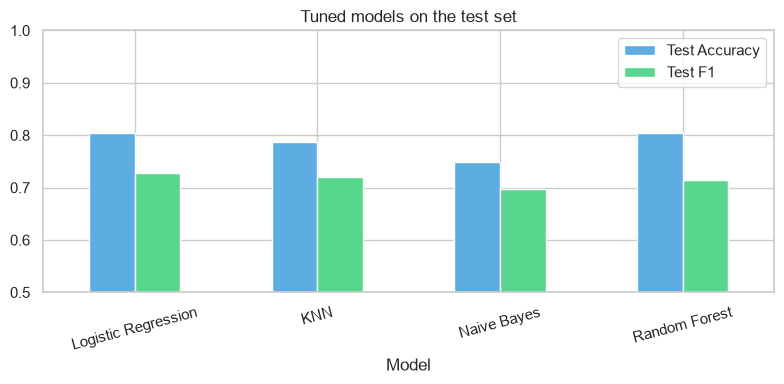

In [24]:
# Bar chart comparing all tuned models
results[["Test Accuracy", "Test F1"]].plot.bar(figsize=(8, 4), rot=15, color=["#5dade2", "#58d68d"])
plt.ylim(0.5, 1); plt.title("Tuned models on the test set"); plt.tight_layout()
plt.savefig("images/model_comparison.png", dpi=120); plt.show()

## 7. Save the Model for Deployment

In [25]:
# Save the full pipeline (preprocessing + model) so the app only needs raw inputs
joblib.dump(best_model, "models/titanic_model.joblib")
print("Saved -> models/titanic_model.joblib")

# Sanity check: reload and predict one example passenger
loaded = joblib.load("models/titanic_model.joblib")
example = pd.DataFrame([{"Age": 28, "Fare_log": np.log1p(30), "FamilySize": 1, "Pclass": 2, "Embarked": 2, "Sex": 1, "IsAlone": 1}])[ALL_FEATURES]
print("Survival probability for a 28-year-old woman, 2nd class:", round(loaded.predict_proba(example)[0, 1], 3))

Saved -> models/titanic_model.joblib
Survival probability for a 28-year-old woman, 2nd class: 0.881


## 8. Conclusions
- **Sex and passenger class** are the strongest drivers of survival: women and 1st-class passengers survived at far higher rates ("women and children first", and better access to lifeboats for upper decks).
- Fare (a proxy for wealth), age and family size add smaller but real signal.
- Data quality matters: the dataset's last 418 rows had placeholder labels and were excluded.
- The best model (chosen by cross-validated F1) is saved and served through the Streamlit app (`app.py`).
- **Limitations:** only 891 labeled rows; the model reflects 1912 historical data and is for learning, not real-world decisions.